# 第191章: RealNVP — カップリング層

## Real-valued Non-Volume Preserving transformations

---

### このノートブックの位置づけ

190 で、フローの層が満たすべき3条件を**実測で**確かめました。

| 条件 | 190 での実測 | 問題 |
|---|---|---|
| 可逆 | $z^2$ では質量が 0.5000 になった | 可逆な層しか使えない |
| $\log\lvert\det J\rvert$ が安い | $d=2048$ で一般行列は対角積の 3 桁倍 | 一般のニューラルネットは使えない |
| $f^{-1}$ が安い | ニュートン法は**発散**、二分法は 80 反復 | 反復は遅く、収束も保証されない |

本章の **アフィンカップリング層** は、この3つを**同時に**満たします。しかも
トリックは「入力を半分に割り、片方はそのまま通す」だけです。

$$x = (x_a, x_b) \;\longmapsto\; z = \big(\underbrace{x_a}_{\text{恒等}},\;
\underbrace{x_b \odot e^{s(x_a)} + t(x_a)}_{\text{アフィン}}\big)$$

$s, t$ は**任意のニューラルネット**で構いません。$x_a$ しか見ないので、
ヤコビアンが三角行列になり、逆写像が閉形式で書けます。
「表現力をニューラルネットに丸投げしつつ、可逆性と行列式を構造で保証する」
のがこの発明の中身です。

### 学習目標

- [ ] アフィンカップリング層を実装し、ヤコビアンが三角行列であることを autograd で確認できる
- [ ] $\log\lvert\det J\rvert = \sum s(x_a)$ を3通り（autograd / 解析式 / 対角積）で一致させられる
- [ ] 逆写像が**1回の前向き計算**で書けることを示し、残差が丸め誤差だけであることを確認できる
- [ ] マスクを交互にしない場合に何が壊れるかを測定し、**層を増やしても直らない**ことを示せる
- [ ] 2次元分布で厳密な対数尤度を出し、解析的な下限と比べられる
- [ ] 画像データで **bits/dim** を計算でき、量子化解除とロジット変換の必要性を説明できる
- [ ] 層数と bits/dim のトレードオフを測定できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **190** | **変数変換とヤコビアン（本章の直接の前提）** |
| 31 | 最尤推定 |
| 33 | 混合ガウスモデル（2次元の目標分布に使う） |
| 09 | MLP（$s, t$ をこれで作る） |
| 38 | VAE 実装（ELBO との対比。MNIST の扱いも） |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

> ⏱ **実行時間**: CPU で約5分です（MNIST の学習が 70秒、層数のアブレーションが 100秒）。

## 目次

1. [環境セットアップ](#setup)
2. [カップリング層 — 3つの要求を同時に満たす](#coupling)
3. [逆写像は厳密か — 残差の正体](#inverse)
4. [マスクを交互にする理由](#masks)
5. [2次元分布で厳密尤度を出す](#twod)
6. [log|det| のコストを 190 と比べる](#cost)
7. [画像で bits/dim を出す](#bpd)
8. [まとめとチートシート](#summary)
9. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


<a id="coupling"></a>
## 2. カップリング層 — 3つの要求を同時に満たす

### 定義

入力 $x \in \mathbb{R}^d$ を二値マスク $m \in \{0,1\}^d$ で2つに割ります。
$m_i = 1$ の成分を $x_a$（通す側）、$m_i = 0$ の成分を $x_b$（変換される側）とします。

$$z_a = x_a, \qquad z_b = x_b \odot \exp\big(s(x_a)\big) + t(x_a)$$

$s, t: \mathbb{R}^{d} \to \mathbb{R}^{d}$ は**任意のニューラルネット**です
（入力は $x \odot m$ とマスクして渡すので、実質 $x_a$ しか見ません）。

### なぜヤコビアンが三角行列になるか

$$J = \frac{\partial z}{\partial x} =
\begin{pmatrix}
I & 0 \\[2pt]
\dfrac{\partial z_b}{\partial x_a} & \mathrm{diag}\big(e^{s(x_a)}\big)
\end{pmatrix}$$

右上が $0$ なのは $z_a = x_a$ が $x_b$ に**依存しない**から。
右下が対角なのは $z_b$ の第 $i$ 成分が $x_b$ の第 $i$ 成分にしか依存しないからです
（$s, t$ は $x_a$ しか見ないので $x_b$ の他の成分が入ってこない）。
左下 $\partial z_b / \partial x_a$ は何が入っていても構いません — **行列式に効かない**。

$$\log\lvert\det J\rvert = \sum_{i : m_i = 0} s_i(x_a)$$

計算量は $O(d)$ の**ただの和**です。$s$ を出すニューラルネットの計算量は別途かかりますが、
それは「行列式のための追加コスト」ではありません。

### なぜ逆写像が閉形式になるか

$z_a = x_a$ なので、**$z$ を見れば $x_a$ がそのまま分かります**。
だから $s(x_a), t(x_a)$ を $z$ から直接計算できて、

$$x_a = z_a, \qquad x_b = \big(z_b - t(z_a)\big) \odot \exp\big(-s(z_a)\big)$$

$s, t$ の**前向き計算を1回**やるだけです。$s, t$ を逆向きに解く必要は一切ありません
（だから $s, t$ は可逆でなくてよい = 任意のネットでよい）。
190 の二分法 80 反復と比べてください。

In [2]:
# ============================================================
# アフィンカップリング層
# ============================================================

class AffineCoupling(nn.Module):
    # m_i = 1 の成分はそのまま通し、m_i = 0 の成分を x_a 依存のアフィン変換にかける
    def __init__(self, d, mask, hidden=64):
        super().__init__()
        self.register_buffer("mask", mask.float())
        self.net = nn.Sequential(
            nn.Linear(d, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2 * d),
        )
        # 最終層をゼロ初期化すると s=t=0、つまり初期状態が恒等写像になる。
        # 学習の最初から log|det| = 0 で安定する（フローの定番の初期化）。
        self.net[-1].weight.data.zero_()
        self.net[-1].bias.data.zero_()

    def _scale_translate(self, x):
        h = self.net(x * self.mask)        # x_a しか見せない
        s, t = h.chunk(2, dim=-1)
        s = torch.tanh(s) * 2.0            # exp(s) が爆発しないよう |s| <= 2 に抑える
        return s * (1 - self.mask), t * (1 - self.mask)

    def forward(self, x):
        # x -> z と log|det J|
        s, t = self._scale_translate(x)
        z = x * self.mask + (1 - self.mask) * (x * torch.exp(s) + t)
        return z, s.sum(-1)

    def inverse(self, z):
        # z -> x。z_a = x_a なので同じ s, t が z から計算できる = 前向き計算1回
        s, t = self._scale_translate(z)
        return z * self.mask + (1 - self.mask) * ((z - t) * torch.exp(-s))


print("カップリング層を定義しました")

カップリング層を定義しました


In [3]:
# ============================================================
# 性質1: ヤコビアンは本当に三角行列か（autograd で確認）
# ============================================================

d_demo = 6
mask_demo = torch.zeros(d_demo)
mask_demo[: d_demo // 2] = 1.0        # 前半を「通す側」にする

torch.manual_seed(1)
layer = AffineCoupling(d_demo, mask_demo)
# ゼロ初期化のままだと恒等写像なので、確認のため重みをランダムにする
for p in layer.net.parameters():
    p.data.normal_(0, 0.3)

x_demo = torch.randn(1, d_demo, requires_grad=True)
J = torch.autograd.functional.jacobian(
    lambda v: layer(v)[0].squeeze(0), x_demo
).squeeze().detach()

print("ヤコビアン行列（小数2桁）:")
print(np.round(J.numpy(), 2))
print()
upper = np.triu(np.abs(J.numpy()), 1).sum()
lower = np.tril(np.abs(J.numpy()), -1).sum()
print(f"上三角部分（対角より上）の絶対値和: {upper:.6f}   <- 0 であるべき")
print(f"下三角部分（対角より下）の絶対値和: {lower:.6f}   <- 何が入っていてもよい")

ヤコビアン行列（小数2桁）:
[[ 1.    0.    0.    0.    0.    0.  ]
 [ 0.    1.    0.    0.    0.    0.  ]
 [ 0.    0.    1.    0.    0.    0.  ]
 [ 1.15  1.04  1.14  0.39  0.    0.  ]
 [-0.   -2.12 -4.09  0.    4.23  0.  ]
 [ 0.88  0.87  3.69  0.    0.    6.54]]

上三角部分（対角より上）の絶対値和: 0.000000   <- 0 であるべき
下三角部分（対角より下）の絶対値和: 14.988396   <- 何が入っていてもよい


In [4]:
# ============================================================
# 性質2: log|det J| は3通りで一致するか
# ============================================================

_, logdet_analytic = layer(x_demo)
_, logdet_autograd = torch.linalg.slogdet(J)
logdet_diagprod = torch.diagonal(J).abs().log().sum()

print(f"(1) autograd のヤコビアンの slogdet : {logdet_autograd.item():.10f}")
print(f"(2) 解析式 sum(s(x_a))              : {logdet_analytic.item():.10f}")
print(f"(3) 対角成分の積の log              : {logdet_diagprod.item():.10f}")
print()
print(f"最大差: {max(abs(logdet_autograd.item() - logdet_analytic.item()), abs(logdet_diagprod.item() - logdet_analytic.item())):.2e}")

# ============================================================
# 性質3: 逆写像は前向き計算1回で厳密か
# ============================================================

z_demo, _ = layer(x_demo)
x_round = layer.inverse(z_demo)
print()
print(f"往復残差（1層・前向き計算1回）: {(x_round - x_demo).abs().max().item():.2e}")
print("-> 190 の二分法は 80 反復必要だった。ここは 1 回。")

(1) autograd のヤコビアンの slogdet : 2.3902106285
(2) 解析式 sum(s(x_a))              : 2.3902106285
(3) 対角成分の積の log              : 2.3902106285

最大差: 0.00e+00

往復残差（1層・前向き計算1回）: 3.58e-07
-> 190 の二分法は 80 反復必要だった。ここは 1 回。


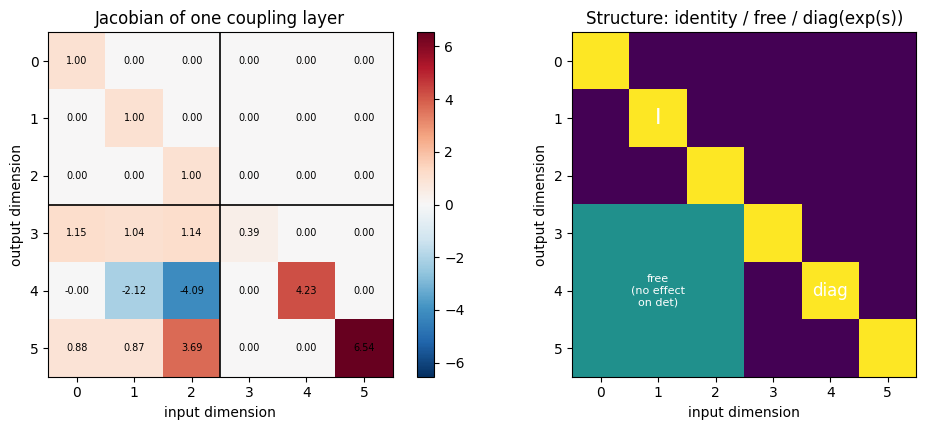

In [5]:
# ============================================================
# 図: ヤコビアンの構造
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

Jn = J.numpy()
vmax = np.abs(Jn).max()
im = axes[0].imshow(Jn, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_title("Jacobian of one coupling layer")
axes[0].set_xlabel("input dimension")
axes[0].set_ylabel("output dimension")
axes[0].set_xticks(range(d_demo))
axes[0].set_yticks(range(d_demo))
axes[0].grid(False)
axes[0].axhline(d_demo // 2 - 0.5, color="k", lw=1.2)
axes[0].axvline(d_demo // 2 - 0.5, color="k", lw=1.2)
for i in range(d_demo):
    for j in range(d_demo):
        axes[0].text(j, i, f"{Jn[i, j]:.2f}", ha="center", va="center",
                     fontsize=7, color="k")
plt.colorbar(im, ax=axes[0], fraction=0.046)

mask_img = np.zeros((d_demo, d_demo))
for i in range(d_demo):
    for j in range(d_demo):
        if i < d_demo // 2:
            mask_img[i, j] = 1.0 if i == j else 0.0        # identity block
        elif j < d_demo // 2:
            mask_img[i, j] = 0.5                            # free block
        else:
            mask_img[i, j] = 1.0 if i == j else 0.0        # diagonal exp(s)
axes[1].imshow(mask_img, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Structure: identity / free / diag(exp(s))")
axes[1].set_xlabel("input dimension")
axes[1].set_ylabel("output dimension")
axes[1].set_xticks(range(d_demo))
axes[1].set_yticks(range(d_demo))
axes[1].grid(False)
axes[1].text(1, 1, "I", ha="center", va="center", fontsize=16, color="w")
axes[1].text(1, 4, "free\n(no effect\non det)", ha="center", va="center",
             fontsize=8, color="w")
axes[1].text(4, 4, "diag", ha="center", va="center", fontsize=12, color="w")

plt.tight_layout()
plt.show()

### 読み取れること

- **上三角部分の和がちょうど 0** です。$z_a = x_a$ が $x_b$ に依存しない、という
  設計がそのまま構造として出ています。
- **3通りの $\log\lvert\det J\rvert$ が小数10桁まで一致**しました。
  つまり `s.sum(-1)` という1行が、本当に行列式の対数です。
- **往復残差 $3.6\times10^{-7}$**（1層・float32、機械イプシロン $1.2\times10^{-7}$ と同程度）。
  逆写像は近似でなく代数的に厳密で、残っているのは丸め誤差だけです（次節で確認）。
- 左下のブロック（`free`）には大きな数が入っています。**ここが表現力の置き場**です。
  行列式に効かないので、どんなニューラルネットを入れても計算コストは増えません。

> 💡 **発明の核**: 「表現力」と「扱いやすさ」を**別の場所に分けた**のがカップリング層です。
> 表現力は左下ブロック（任意のネット）、扱いやすさは右上の 0 と右下の対角（構造）。
> 両方を同じ行列に詰め込もうとしないのが上手さです。

<a id="inverse"></a>
## 3. 逆写像は厳密か — 残差の正体

1層では往復残差が 0 でした。層を重ねるとどうなるでしょうか。

**予想**: 代数的に厳密なので、層を重ねても残差は 0 のまま、あるいは
機械精度（float32 なら $10^{-7}$ 程度）に留まる。

確かめます。`float32` と `float64` の両方で測ります。

In [6]:
# ============================================================
# フロー本体（カップリング層を重ねる）
# ============================================================

class RealNVP(nn.Module):
    def __init__(self, d, n_layers=6, alternate=True, hidden=64, mask0=None,
                 dtype=torch.float32):
        super().__init__()
        if mask0 is None:
            mask0 = torch.zeros(d)
            mask0[::2] = 1.0                 # 交互（偶数番を通す）
        layers = []
        for i in range(n_layers):
            # alternate=False なら全層が同じマスク（あとで壊れることを見る）
            m = mask0 if (not alternate or i % 2 == 0) else 1.0 - mask0
            layers.append(AffineCoupling(d, m, hidden))
        self.layers = nn.ModuleList(layers)
        self.d = d
        self.to(dtype)

    def forward(self, x):
        log_det = torch.zeros(x.shape[0], dtype=x.dtype)
        for layer in self.layers:
            x, ld = layer(x)
            log_det = log_det + ld           # 190 で確かめた「合成は足し算」
        return x, log_det

    def inverse(self, z):
        for layer in reversed(self.layers):  # 逆順に逆写像を当てる
            z = layer.inverse(z)
        return z

    def log_prob(self, x):
        z, log_det = self(x)
        return (-0.5 * z**2 - 0.5 * math.log(2 * math.pi)).sum(-1) + log_det


print("RealNVP を定義しました")

RealNVP を定義しました


In [7]:
# ============================================================
# 往復残差: float32 vs float64、1層 vs 6層
# ============================================================

rows = []
for dtype, name in [(torch.float32, "float32"), (torch.float64, "float64")]:
    for n_layers in [1, 6]:
        torch.manual_seed(3)
        f = RealNVP(2, n_layers=n_layers, dtype=dtype)
        for p in f.parameters():
            p.data.normal_(0, 0.3)           # 恒等写像から外す
        z = torch.randn(5000, 2, dtype=dtype)
        x = f.inverse(z).detach()
        with torch.no_grad():
            resid = float((f(x)[0] - z).abs().max())
        rows.append((name, n_layers, resid))
        print(f"{name} / {n_layers}層: 往復残差 {resid:.2e}")

eps32 = np.finfo(np.float32).eps
eps64 = np.finfo(np.float64).eps
print()
print(f"参考: float32 の機械イプシロン {eps32:.2e} / float64 {eps64:.2e}")
r32_1 = [r for r in rows if r[0] == "float32" and r[1] == 1][0][2]
r32_6 = [r for r in rows if r[0] == "float32" and r[1] == 6][0][2]
print(f"float32 で 1層 -> 6層 の残差の増幅: {r32_6 / r32_1:.0f} 倍")

float32 / 1層: 往復残差 7.15e-07
float32 / 6層: 往復残差 3.08e-03
float64 / 1層: 往復残差 8.88e-16
float64 / 6層: 往復残差 3.61e-12

参考: float32 の機械イプシロン 1.19e-07 / float64 2.22e-16
float32 で 1層 -> 6層 の残差の増幅: 4303 倍


### 読み取れること — 予想は半分外れた（警告つき）

残差は 0 のままではありませんでした。

| | 1層 | 6層 | 増幅 |
|---|---|---|---|
| float32 | $7.2 \times 10^{-7}$ | $3.1 \times 10^{-3}$ | 約 4300 倍 |
| float64 | $8.9 \times 10^{-16}$ | $3.6 \times 10^{-12}$ | 約 4100 倍 |

**float64 にすると残差が $10^{-12}$ まで落ちます。** これが決定的です。
アルゴリズムが近似なら精度を上げても残差は減りません。減ったので、
**逆写像は代数的に厳密で、残差は丸め誤差**だと確定します。

増幅の機構: 各層が $x_b \mapsto x_b e^{s} + t$ をかけるので、逆写像では
$e^{-s}$ を掛けます。本実装は $\lvert s\rvert \le 2$ に抑えているので
1層あたり最大 $e^2 \approx 7.4$ 倍。6層で最悪 $7.4^6 \approx 1.6\times10^5$ 倍まで
誤差が増幅されうる計算で、実測の 4300 倍はその範囲内です
（実際の $s$ は上限いっぱいではないので、最悪値より小さく出ます）。

> ⚠️ **実務上の注意**: 深いフロー（RealNVP の原論文は数十層）を float32 で
> 逆向きに使うと、**サンプリングした $x$ を再び $f$ に通しても元の $z$ に戻らない**
> ことがあります。生成そのものには影響しませんが、
> 「往復が合うか」をテストに書くときは**許容誤差を層数に応じて緩める**か、
> float64 で検証する必要があります。
> 190 の反復法と違い「収束しない」ことはありませんが、**精度は無料ではありません**。

<a id="masks"></a>
## 4. マスクを交互にする理由

カップリング層は入力の**半分をそのまま通します**。マスクを固定したまま層を重ねると、
その半分は**何層通しても変わりません**。

$$x_a \to x_a \to x_a \to \cdots$$

つまり $z_a$ の分布はデータの $x_a$ の分布そのままで、標準正規になりようがありません。

**予想**: 固定マスクでは NLL が悪化する。ただし層を増やせば、変換される側（$x_b$）が
$x_a$ の情報を吸収して、ある程度は補えるかもしれない。

2次元の4峰混合ガウスで測ります。真の密度が解析的に書けるので
**到達可能な下限**が出ます（190 と同じ方針）。

In [8]:
# ============================================================
# 目標分布: 2次元・4峰の混合ガウス（真の密度が解析的に分かる）
# ============================================================

MUS = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD = 0.5

def sample_gmm2d(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS[k] + r.standard_normal((n, 2)) * SD).astype(np.float32)

def logsumexp_np(a, axis):
    # 47 章で学んだ logsumexp。素朴な log(sum(exp)) はアンダーフローする
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def gmm2d_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD**2 - np.log(2 * np.pi * SD**2)
             for m in MUS]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X2_train = sample_gmm2d(8000, seed=0)
X2_test = sample_gmm2d(4000, seed=1)
nll_lb_2d = float(-gmm2d_logpdf(X2_test).mean())
print(f"真の分布の test NLL（到達可能な下限）: {nll_lb_2d:.4f}")

真の分布の test NLL（到達可能な下限）: 2.8275


In [9]:
# ============================================================
# 固定マスク vs 交互マスク × 層数
# ============================================================

def train_2d(alternate, n_layers, epochs=1200, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    f = RealNVP(2, n_layers=n_layers, alternate=alternate)
    opt = torch.optim.Adam(f.parameters(), lr=lr)
    X = torch.tensor(X2_train)
    hist = []
    for _ in range(epochs):
        loss = -f.log_prob(X).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        hist.append(float(loss.detach()))
    with torch.no_grad():
        te = float(-f.log_prob(torch.tensor(X2_test)).mean())
    return f, np.array(hist), te

t0 = time.time()
mask_rows = []
for alternate in [False, True]:
    for n_layers in [2, 6, 12]:
        f, hist, te = train_2d(alternate, n_layers)
        mask_rows.append({"alternate": alternate, "n_layers": n_layers,
                          "test_nll": te, "hist": hist, "flow": f})
        tag = "交互" if alternate else "固定"
        print(f"{tag}マスク {n_layers:2d}層: test NLL {te:.4f}  "
              f"（下限まで {te - nll_lb_2d:+.4f}）")
print(f"\n学習時間 {time.time() - t0:.1f}s")

# 固定マスクで何が起きているか: z の各次元の標準偏差を見る
f_fixed = [r for r in mask_rows if not r["alternate"] and r["n_layers"] == 12][0]["flow"]
f_alt = [r for r in mask_rows if r["alternate"] and r["n_layers"] == 12][0]["flow"]
with torch.no_grad():
    z_fixed, _ = f_fixed(torch.tensor(X2_test))
    z_alt, _ = f_alt(torch.tensor(X2_test))
print()
print("z の各次元の標準偏差（1.0 になるべき）:")
print(f"  固定マスク 12層: 次元0 {z_fixed[:, 0].std():.4f}  次元1 {z_fixed[:, 1].std():.4f}")
print(f"  交互マスク 12層: 次元0 {z_alt[:, 0].std():.4f}  次元1 {z_alt[:, 1].std():.4f}")
print(f"  参考: データ x の標準偏差 次元0 {X2_test[:, 0].std():.4f}")
print()
print("-> 固定マスクでは次元0 がデータのまま。12層通しても一度も変換されていない。")

固定マスク  2層: test NLL 5.1819  （下限まで +2.3544）


固定マスク  6層: test NLL 5.1826  （下限まで +2.3550）


固定マスク 12層: test NLL 5.1817  （下限まで +2.3541）


交互マスク  2層: test NLL 3.2675  （下限まで +0.4399）


交互マスク  6層: test NLL 2.8779  （下限まで +0.0504）


交互マスク 12層: test NLL 2.8644  （下限まで +0.0368）

学習時間 65.2s

z の各次元の標準偏差（1.0 になるべき）:
  固定マスク 12層: 次元0 2.0595  次元1 1.0042
  交互マスク 12層: 次元0 1.0093  次元1 0.9787
  参考: データ x の標準偏差 次元0 2.0592

-> 固定マスクでは次元0 がデータのまま。12層通しても一度も変換されていない。


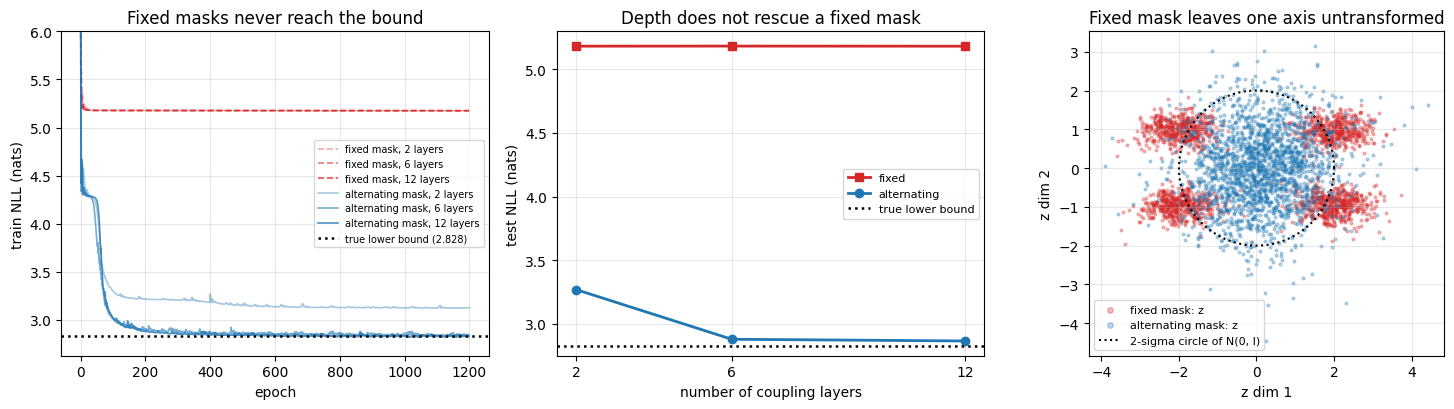

In [10]:
# ============================================================
# 図: マスクの選び方と層数
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for r in mask_rows:
    style = "-" if r["alternate"] else "--"
    color = "tab:blue" if r["alternate"] else "tab:red"
    label = f"{'alternating' if r['alternate'] else 'fixed'} mask, {r['n_layers']} layers"
    axes[0].plot(r["hist"], style, lw=1.2, color=color, alpha=0.4 + 0.2 * [2, 6, 12].index(r["n_layers"]),
                 label=label)
axes[0].axhline(nll_lb_2d, color="k", ls=":", lw=1.8, label=f"true lower bound ({nll_lb_2d:.3f})")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("train NLL (nats)")
axes[0].set_title("Fixed masks never reach the bound")
axes[0].set_ylim(nll_lb_2d - 0.2, 6.0)
axes[0].legend(fontsize=7)

depths = [2, 6, 12]
for alternate, color, marker in [(False, "tab:red", "s"), (True, "tab:blue", "o")]:
    ys = [r["test_nll"] for r in mask_rows if r["alternate"] == alternate]
    axes[1].plot(depths, ys, marker + "-", lw=2, color=color,
                 label="alternating" if alternate else "fixed")
axes[1].axhline(nll_lb_2d, color="k", ls=":", lw=1.8, label="true lower bound")
axes[1].set_xlabel("number of coupling layers")
axes[1].set_ylabel("test NLL (nats)")
axes[1].set_title("Depth does not rescue a fixed mask")
axes[1].set_xticks(depths)
axes[1].legend(fontsize=8)

sub = np.random.default_rng(0).choice(len(X2_test), 2000, replace=False)
axes[2].scatter(z_fixed[sub, 0], z_fixed[sub, 1], s=4, alpha=0.3,
                color="tab:red", label="fixed mask: z")
axes[2].scatter(z_alt[sub, 0], z_alt[sub, 1], s=4, alpha=0.3,
                color="tab:blue", label="alternating mask: z")
theta = np.linspace(0, 2 * np.pi, 200)
axes[2].plot(2 * np.cos(theta), 2 * np.sin(theta), "k:", lw=1.5,
             label="2-sigma circle of N(0, I)")
axes[2].set_aspect("equal")
axes[2].set_xlabel("z dim 1")
axes[2].set_ylabel("z dim 2")
axes[2].set_title("Fixed mask leaves one axis untransformed")
axes[2].legend(fontsize=8, markerscale=2)

plt.tight_layout()
plt.show()

### 読み取れること — 予想の後半は外れた

| マスク | 2層 | 6層 | 12層 |
|---|---|---|---|
| 固定 | 5.1819 | 5.1826 | 5.1817 |
| 交互 | 3.2675 | 2.8779 | 2.8644 |

**固定マスクは層を増やしても一切改善しません**（5.18 で完全に平ら）。
「層を増やせば $x_b$ 側が補うかもしれない」という予想は外れました。

機構は右の図が示しています。固定マスクでは $z$ の次元0 の標準偏差が **2.06**、
これはデータ $x$ の次元0 の標準偏差 **2.06** と一致します。
**12層通して一度も変換されていない**のです。恒等写像を12回合成しても恒等写像です。

> 📌 これは 47 章（MDN）の「**モデルを大きくしても直らない**」と同じ構造の話です。
> あちらは損失関数の性質、こちらは**アーキテクチャの構造**が原因で、
> どちらも規模では解決しません。「学習が足りないのか、構造が間違っているのか」は
> **層数を変えて平らかどうか見る**のが最も安い切り分けです。

交互マスクは 6層で下限 2.8275 まで残り 0.050 nats に到達しました。
12層でもほぼ同じ（残り 0.037 nats）なので、この分布には 6層で足りています。

<a id="twod"></a>
## 5. 2次元分布で厳密尤度を出す

交互マスク 6層のフローで、学習した密度・サンプル・潜在空間を見ます。
**密度の値は厳密**なので、等高線はそのまま信じてよい図です（VAE の ELBO と違います）。

In [11]:
# ============================================================
# 学習済みフローの密度・サンプル・潜在空間
# ============================================================

flow2d = [r for r in mask_rows if r["alternate"] and r["n_layers"] == 6][0]["flow"]
nll_2d = [r for r in mask_rows if r["alternate"] and r["n_layers"] == 6][0]["test_nll"]

# 密度のグリッド評価
gx = np.linspace(-4.5, 4.5, 220)
GX, GY = np.meshgrid(gx, gx)
grid = torch.tensor(np.stack([GX.ravel(), GY.ravel()], -1), dtype=torch.float32)
with torch.no_grad():
    dens_flow = flow2d.log_prob(grid).exp().numpy().reshape(GX.shape)
dens_true = np.exp(gmm2d_logpdf(np.stack([GX, GY], -1)))

# 密度の積分（厳密尤度の検算）
cell = (gx[1] - gx[0]) ** 2
print(f"学習したフロー密度のグリッド積分: {dens_flow.sum() * cell:.5f}  (1 になるべき)")
print(f"真の密度のグリッド積分          : {dens_true.sum() * cell:.5f}")
print()
print(f"フロー test NLL {nll_2d:.4f} / 下限 {nll_lb_2d:.4f} -> 差 {nll_2d - nll_lb_2d:.4f} nats")

# サンプリング（逆写像1パス）
torch.manual_seed(2)
z_draw = torch.randn(20000, 2)
t0 = time.time()
x_samp = flow2d.inverse(z_draw).detach().detach()
t_sample = time.time() - t0
with torch.no_grad():
    resid_2d = float((flow2d(x_samp)[0] - z_draw).abs().max())
print()
print(f"2万点のサンプリング: {t_sample * 1000:.2f} ms（逆写像1パス）, 往復残差 {resid_2d:.2e}")
print(f"サンプルの平均 {x_samp.mean(0).numpy().round(3)} / データ {X2_train.mean(0).round(3)}")
print(f"サンプルの標準偏差 {x_samp.std(0).numpy().round(3)} / データ {X2_train.std(0).round(3)}")

学習したフロー密度のグリッド積分: 0.99929  (1 になるべき)
真の密度のグリッド積分          : 1.00000

フロー test NLL 2.8779 / 下限 2.8275 -> 差 0.0504 nats

2万点のサンプリング: 10.22 ms（逆写像1パス）, 往復残差 9.10e-05
サンプルの平均 [-0.028  0.02 ] / データ [ 0.003 -0.004]
サンプルの標準偏差 [2.07  2.068] / データ [2.058 2.058]


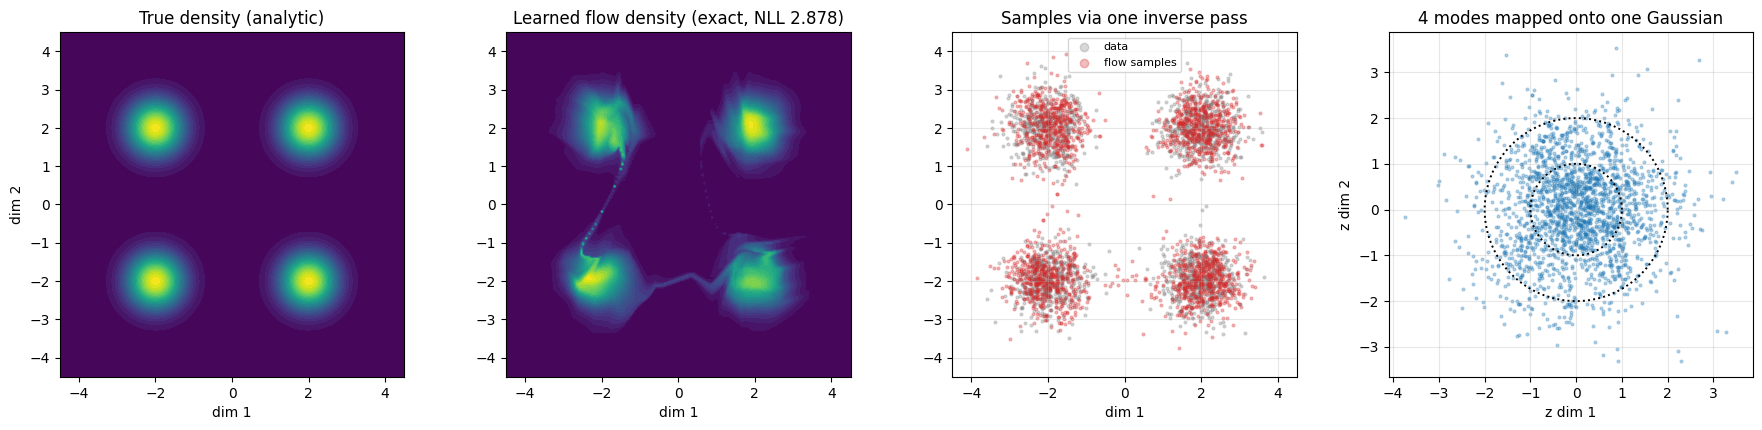

In [12]:
# ============================================================
# 図: 厳密な密度とサンプル
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

axes[0].contourf(GX, GY, dens_true, levels=30, cmap="viridis")
axes[0].set_aspect("equal")
axes[0].set_title("True density (analytic)")
axes[0].set_xlabel("dim 1")
axes[0].set_ylabel("dim 2")
axes[0].grid(False)

axes[1].contourf(GX, GY, dens_flow, levels=30, cmap="viridis")
axes[1].set_aspect("equal")
axes[1].set_title(f"Learned flow density (exact, NLL {nll_2d:.3f})")
axes[1].set_xlabel("dim 1")
axes[1].grid(False)

xs = x_samp.numpy()
axes[2].scatter(X2_test[:2000, 0], X2_test[:2000, 1], s=4, alpha=0.3,
                color="tab:gray", label="data")
axes[2].scatter(xs[:2000, 0], xs[:2000, 1], s=4, alpha=0.3,
                color="tab:red", label="flow samples")
axes[2].set_aspect("equal")
axes[2].set_xlim(-4.5, 4.5)
axes[2].set_ylim(-4.5, 4.5)
axes[2].set_xlabel("dim 1")
axes[2].set_title("Samples via one inverse pass")
axes[2].legend(fontsize=8, markerscale=3)

with torch.no_grad():
    z_test, _ = flow2d(torch.tensor(X2_test))
axes[3].scatter(z_test[:2000, 0], z_test[:2000, 1], s=4, alpha=0.3, color="tab:blue")
theta = np.linspace(0, 2 * np.pi, 200)
for k in [1, 2]:
    axes[3].plot(k * np.cos(theta), k * np.sin(theta), "k:", lw=1.4)
axes[3].set_aspect("equal")
axes[3].set_xlabel("z dim 1")
axes[3].set_ylabel("z dim 2")
axes[3].set_title("4 modes mapped onto one Gaussian")

plt.tight_layout()
plt.show()

<a id="cost"></a>
## 6. log|det| のコストを 190 と比べる

190 で「一般行列の行列式は高い」と測りました。カップリング層の
$\log\lvert\det J\rvert$ は `s.sum(-1)` という**ただの和**です。
同じ $d$ で比べます。

In [13]:
# ============================================================
# log|det| のコスト: カップリング層（和）vs 一般行列（slogdet）
# ============================================================

def bench(fn, reps):
    for _ in range(3):
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps

cost_rows = []
for dd in [196, 784, 3072]:
    s_batch = torch.randn(256, dd)          # バッチ 256 の s(x_a)
    M = torch.randn(dd, dd)
    t_sum = bench(lambda: s_batch.sum(-1), 200)
    t_det = bench(lambda: torch.linalg.slogdet(M), 50)
    cost_rows.append((dd, t_sum, t_det))
    print(f"d={dd:5d}: カップリング（和・バッチ256） {t_sum*1e6:7.1f} us   "
          f"一般行列 slogdet（1枚） {t_det*1e6:9.1f} us   比 {t_det/t_sum:7.1f}x")

print()
print("注意: 左はバッチ256本ぶんの log|det| を一度に出している。")
print("      右は行列1枚ぶん。1サンプルあたりで比べると差はさらに大きい。")
print(f"d=3072（32x32 カラー画像相当）で {cost_rows[-1][2]/cost_rows[-1][1]:.0f} 倍。")
print("これが「ヤコビアンを三角にする」という設計圧力の正体（190 第5節の続き）。")

d=  196: カップリング（和・バッチ256）    17.1 us   一般行列 slogdet（1枚）     110.0 us   比     6.4x
d=  784: カップリング（和・バッチ256）    19.6 us   一般行列 slogdet（1枚）    1074.3 us   比    54.7x


d= 3072: カップリング（和・バッチ256）    28.7 us   一般行列 slogdet（1枚）   24692.5 us   比   859.0x

注意: 左はバッチ256本ぶんの log|det| を一度に出している。
      右は行列1枚ぶん。1サンプルあたりで比べると差はさらに大きい。
d=3072（32x32 カラー画像相当）で 859 倍。
これが「ヤコビアンを三角にする」という設計圧力の正体（190 第5節の続き）。


<a id="bpd"></a>
## 7. 画像で bits/dim を出す

### なぜ量子化解除（dequantization）が必要か

画像の画素は $\{0, 1, \dots, 255\}$ の**離散値**です。連続密度モデルを離散データに
そのまま最尤で当てると、密度が各整数点に**デルタ関数的に尖って尤度が無限大**に
発散します。目的関数に上限がないので、学習は意味を失います。

対策は**一様ノイズを足して連続化**することです。

$$v = \frac{k + u}{256}, \qquad u \sim \mathcal{U}[0, 1)$$

これは単なる誤魔化しではありません。$v$ の連続密度の対数尤度は、
元の離散分布の対数尤度の**下界**になることが示せます
（Theis et al., 2016）。つまり**安全側に評価している**ことになります。

### なぜロジット変換が必要か

$v \in [0,1]$ は有界ですが、フローの基底は $\mathbb{R}^d$ 上の標準正規です。
有界区間を全空間に伸ばすため、ロジット変換を挟みます。

$$y = \mathrm{logit}\big(\alpha + (1-2\alpha) v\big), \qquad \alpha = 0.05$$

$\alpha$ は $v = 0$ や $v = 1$ で $\mathrm{logit}$ が発散しないための余裕です。
これも可逆な変換なので、**ヤコビアンを足し込めば**厳密尤度のままです。

$$\frac{dy}{dv} = \frac{1-2\alpha}{\sigma(1-\sigma)}, \qquad \sigma = \alpha + (1-2\alpha)v$$

### bits/dim の定義

離散画素値 $k$ に対する確率 $P(k)$ の符号長を1次元あたりのビットで表します。

$$\text{bits/dim} = -\frac{\log_2 P(k)}{d}$$

ビン幅 $1/256$ で $P(k) \approx p_V(v) \cdot 256^{-d}$ と近似すると

$$\text{bits/dim} = -\frac{\log p_V(v)}{d \ln 2} + 8$$

**一様分布（何も学習していないモデル）がちょうど 8 bits/dim** になります。
これが上限の基準です。

In [14]:
# ============================================================
# MNIST を 14x14 に落として読み込む（計算量のため）
# ============================================================

from torchvision import datasets

# data ディレクトリの場所はノートブックの起動位置によって違う
candidates = ["data", "notebooks/generative/data", "../generative/data",
              os.path.join(os.getcwd(), "data")]
data_root = None
for c in candidates:
    if os.path.isdir(os.path.join(c, "MNIST")):
        data_root = c
        break
if data_root is None:
    raise FileNotFoundError(f"MNIST が見つかりません。探した場所: {candidates}")
print("MNIST の場所:", data_root)

mnist = datasets.MNIST(data_root, train=True, download=False)
imgs = mnist.data.float()                                  # [60000, 28, 28], 0..255
imgs = F.avg_pool2d(imgs.unsqueeze(1), 2).squeeze(1)       # 14x14 に平均プーリング
imgs = imgs.round().clamp(0, 255)                          # 整数に戻す（量子化を保つ）

H = W = 14
D_IMG = H * W
N_TRAIN = 56000
X_img_train = imgs[:N_TRAIN].reshape(N_TRAIN, -1)
X_img_test = imgs[N_TRAIN:60000].reshape(-1, D_IMG)
print(f"次元 d = {D_IMG}  訓練 {tuple(X_img_train.shape)}  テスト {tuple(X_img_test.shape)}")
print(f"画素値の範囲: [{X_img_train.min():.0f}, {X_img_train.max():.0f}]（整数）")

MNIST の場所: notebooks/generative/data
次元 d = 196  訓練 (56000, 196)  テスト (4000, 196)
画素値の範囲: [0, 255]（整数）


In [15]:
# ============================================================
# 量子化解除 + ロジット変換 と bits/dim の換算
# ============================================================

ALPHA = 0.05

def dequantize_logit(k, generator=None):
    # k: 0..255 の整数画素 -> y（実数空間）と log|dy/dv|
    u = torch.rand(k.shape, generator=generator)
    v = (k + u) / 256.0
    sig = ALPHA + (1 - 2 * ALPHA) * v
    y = torch.log(sig) - torch.log1p(-sig)
    log_det = (math.log(1 - 2 * ALPHA) - torch.log(sig) - torch.log1p(-sig)).sum(-1)
    return y, log_det

def to_bits_per_dim(log_p_y, log_det_yv):
    # log p_V(v) = log p_Y(y) + log|dy/dv|、そこから bits/dim へ
    log_p_v = log_p_y + log_det_yv
    return -log_p_v / (D_IMG * math.log(2)) + 8.0

gen = torch.Generator().manual_seed(7)
Y_train, _ = dequantize_logit(X_img_train, gen)
Y_test, logdet_test = dequantize_logit(X_img_test, gen)

# 基準1: 一様分布（定義どおりちょうど 8）
print("基準1 一様分布                   : 8.0000 bits/dim（定義どおり）")

# 基準2: ロジット空間で画素ごと独立なガウス（依存関係を一切モデル化しない）
mu_px = Y_train.mean(0)
sd_px = Y_train.std(0) + 1e-6
lp_indep = (-0.5 * ((Y_test - mu_px) / sd_px) ** 2 - torch.log(sd_px)
            - 0.5 * math.log(2 * math.pi)).sum(-1)
bpd_indep = float(to_bits_per_dim(lp_indep, logdet_test).mean())
print(f"基準2 独立ガウス（ロジット空間）  : {bpd_indep:.4f} bits/dim")
print()
print("-> フローが基準2 をどれだけ下回るかが「画素間の依存をモデル化できた量」。")

基準1 一様分布                   : 8.0000 bits/dim（定義どおり）
基準2 独立ガウス（ロジット空間）  : 5.0035 bits/dim

-> フローが基準2 をどれだけ下回るかが「画素間の依存をモデル化できた量」。


市松模様マスク: 1 の数 98 / 全体 196


隣接画素が必ず別グループに入るので、1層で「隣から予測する」形になる。
（1次元の偶数奇数マスクを2次元に素直に拡張したもの）


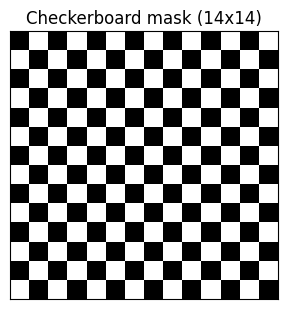

In [16]:
# ============================================================
# 画像用の市松模様（checkerboard）マスク
# ============================================================

def checkerboard_mask(h, w):
    ii, jj = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    return torch.tensor(((ii + jj) % 2).astype(np.float32).ravel())

mask_cb = checkerboard_mask(H, W)
print(f"市松模様マスク: 1 の数 {int(mask_cb.sum())} / 全体 {D_IMG}")
print("隣接画素が必ず別グループに入るので、1層で「隣から予測する」形になる。")
print("（1次元の偶数奇数マスクを2次元に素直に拡張したもの）")

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(mask_cb.numpy().reshape(H, W), cmap="gray")
ax.set_title("Checkerboard mask (14x14)")
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# MNIST で RealNVP を学習する（約70秒）
# ============================================================

def train_image_flow(n_layers=8, hidden=256, epochs=20, batch=256, lr=1e-3,
                     seed=0, verbose=True):
    torch.manual_seed(seed)
    f = RealNVP(D_IMG, n_layers=n_layers, hidden=hidden, mask0=mask_cb)
    opt = torch.optim.Adam(f.parameters(), lr=lr)
    steps_total = epochs * (N_TRAIN // batch)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps_total)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(N_TRAIN)
        for i in range(0, N_TRAIN, batch):
            xb = X_img_train[perm[i:i + batch]]
            yb, _ = dequantize_logit(xb)          # 毎回ノイズを引き直す
            loss = -f.log_prob(yb).mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(f.parameters(), 100.0)
            opt.step()
            sched.step()
        with torch.no_grad():
            bpd = float(to_bits_per_dim(f.log_prob(Y_test), logdet_test).mean())
        hist.append(bpd)
        if verbose:
            print(f"  epoch {ep + 1:2d}: test {bpd:.4f} bits/dim   ({time.time() - t0:.0f}s)")
    return f, hist, time.time() - t0

flow_img, bpd_hist, train_time = train_image_flow()
bpd_flow = bpd_hist[-1]
print()
print(f"学習時間 {train_time:.1f}s")
print(f"パラメータ数 {sum(p.numel() for p in flow_img.parameters()):,}")
print()
print(f"一様分布        8.0000 bits/dim")
print(f"独立ガウス      {bpd_indep:.4f} bits/dim")
print(f"RealNVP         {bpd_flow:.4f} bits/dim   "
      f"（独立ガウスより {bpd_indep - bpd_flow:.4f} bits/dim 改善）")

  epoch  1: test 4.2962 bits/dim   (3s)


  epoch  2: test 3.7034 bits/dim   (7s)


  epoch  3: test 3.6651 bits/dim   (10s)


  epoch  4: test 3.3972 bits/dim   (14s)


  epoch  5: test 3.2591 bits/dim   (17s)


...

  epoch 16: test 2.6941 bits/dim   (54s)


  epoch 17: test 2.6697 bits/dim   (58s)


  epoch 18: test 2.6675 bits/dim   (61s)


  epoch 19: test 2.6557 bits/dim   (65s)


  epoch 20: test 2.6552 bits/dim   (68s)

学習時間 68.0s
パラメータ数 1,735,744

一様分布        8.0000 bits/dim
独立ガウス      5.0035 bits/dim
RealNVP         2.6552 bits/dim   （独立ガウスより 2.3484 bits/dim 改善）


16枚のサンプリング: 2.3 ms（逆写像1パス）
往復残差（8層 float32, d=196）: 5.48e-06


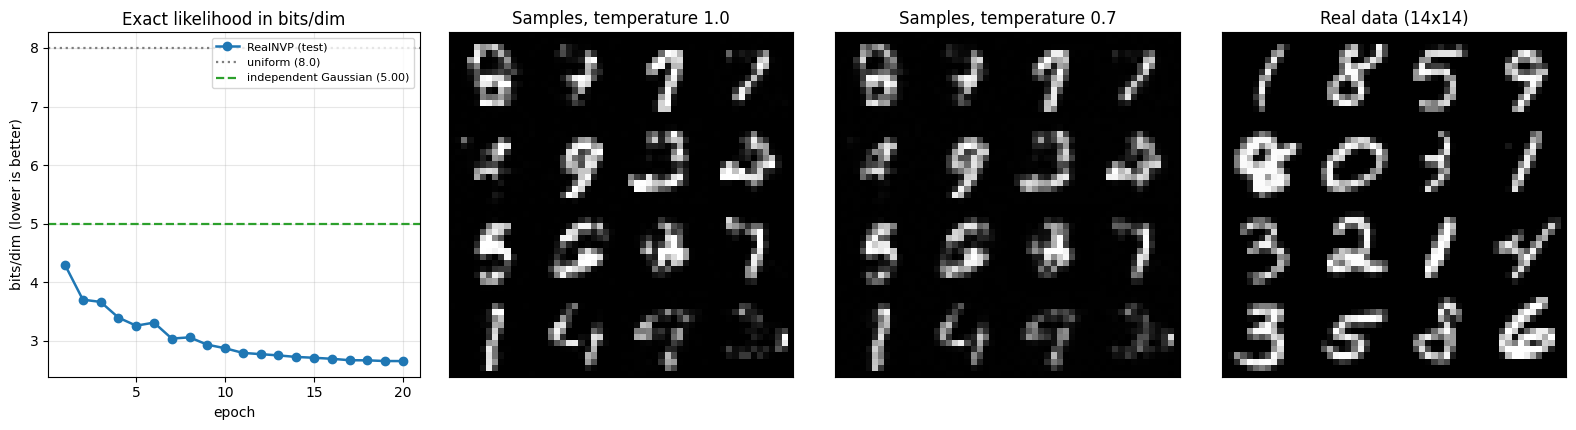

In [18]:
# ============================================================
# サンプリングと図
# ============================================================

@torch.no_grad()
def sample_images(f, n=16, temperature=1.0, seed=0):
    torch.manual_seed(seed)
    z = torch.randn(n, D_IMG) * temperature
    y = f.inverse(z)
    v = torch.sigmoid(y)                       # ロジット変換を戻す
    v = (v - ALPHA) / (1 - 2 * ALPHA)          # [0,1] に戻す
    return v.clamp(0, 1).reshape(n, H, W).numpy()

t0 = time.time()
samples_t10 = sample_images(flow_img, 16, temperature=1.0, seed=1)
t_samp = time.time() - t0
samples_t07 = sample_images(flow_img, 16, temperature=0.7, seed=1)
print(f"16枚のサンプリング: {t_samp * 1000:.1f} ms（逆写像1パス）")

with torch.no_grad():
    rt = flow_img.inverse(flow_img(Y_test[:512])[0])
    print(f"往復残差（8層 float32, d={D_IMG}）: {(rt - Y_test[:512]).abs().max():.2e}")

fig = plt.figure(figsize=(16, 4.4))

ax1 = plt.subplot(1, 4, 1)
ax1.plot(range(1, len(bpd_hist) + 1), bpd_hist, "o-", lw=1.8, color="tab:blue",
         label="RealNVP (test)")
ax1.axhline(8.0, color="tab:gray", ls=":", lw=1.6, label="uniform (8.0)")
ax1.axhline(bpd_indep, color="tab:green", ls="--", lw=1.6,
            label=f"independent Gaussian ({bpd_indep:.2f})")
ax1.set_xlabel("epoch")
ax1.set_ylabel("bits/dim (lower is better)")
ax1.set_title("Exact likelihood in bits/dim")
ax1.legend(fontsize=8)

def grid_plot(ax, arr, title):
    g = np.zeros((4 * H, 4 * W))
    for i in range(16):
        r, c = divmod(i, 4)
        g[r * H:(r + 1) * H, c * W:(c + 1) * W] = arr[i]
    ax.imshow(g, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])

grid_plot(plt.subplot(1, 4, 2), samples_t10, "Samples, temperature 1.0")
grid_plot(plt.subplot(1, 4, 3), samples_t07, "Samples, temperature 0.7")
real = (X_img_test[:16] / 255.0).reshape(16, H, W).numpy()
grid_plot(plt.subplot(1, 4, 4), real, "Real data (14x14)")

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# 層数と bits/dim（各8エポックで固定して比較）
# ============================================================

depth_rows = []
for n_layers in [2, 4, 8, 16]:
    f, hist, tt = train_image_flow(n_layers=n_layers, epochs=8, seed=0, verbose=False)
    with torch.no_grad():
        rr = float((f.inverse(f(Y_test[:512])[0]) - Y_test[:512]).abs().max())
    n_par = sum(p.numel() for p in f.parameters())
    depth_rows.append({"n_layers": n_layers, "bpd": hist[-1], "params": n_par,
                       "resid": rr, "time": tt})
    print(f"{n_layers:2d}層: {hist[-1]:.4f} bits/dim  params {n_par:>9,}  "
          f"往復残差 {rr:.2e}  学習 {tt:.0f}s")

print()
print("注意: 上の 8層 は 8 エポックなので、20 エポック回した本番"
      f"（{bpd_flow:.4f}）より悪い。層数だけを比べるための条件固定。")

 2層: 4.4966 bits/dim  params   433,936  往復残差 2.86e-06  学習 8s


 4層: 3.2040 bits/dim  params   867,872  往復残差 6.20e-06  学習 14s


 8層: 2.8913 bits/dim  params 1,735,744  往復残差 5.96e-06  学習 27s


16層: 2.7904 bits/dim  params 3,471,488  往復残差 6.20e-06  学習 54s

注意: 上の 8層 は 8 エポックなので、20 エポック回した本番（2.6552）より悪い。層数だけを比べるための条件固定。


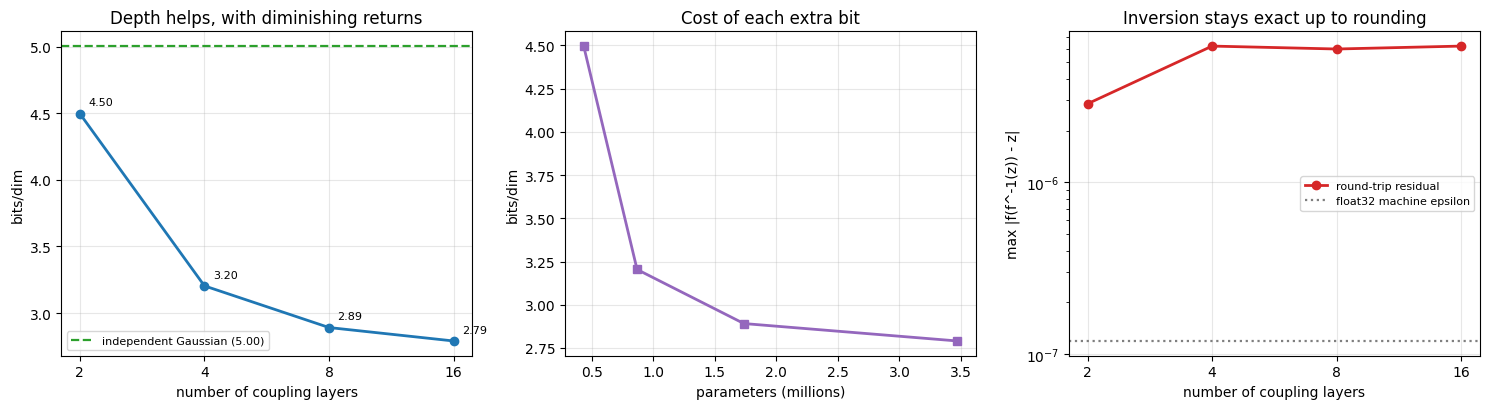

In [20]:
# ============================================================
# 図: 層数のトレードオフ
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

dl = [r["n_layers"] for r in depth_rows]
bl = [r["bpd"] for r in depth_rows]
axes[0].plot(dl, bl, "o-", lw=2, color="tab:blue")
axes[0].axhline(bpd_indep, color="tab:green", ls="--", lw=1.6,
                label=f"independent Gaussian ({bpd_indep:.2f})")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(dl)
axes[0].set_xticklabels(dl)
axes[0].set_xlabel("number of coupling layers")
axes[0].set_ylabel("bits/dim")
axes[0].set_title("Depth helps, with diminishing returns")
axes[0].legend(fontsize=8)
for r in depth_rows:
    axes[0].annotate(f"{r['bpd']:.2f}", (r["n_layers"], r["bpd"]),
                     textcoords="offset points", xytext=(6, 6), fontsize=8)

axes[1].plot([r["params"] / 1e6 for r in depth_rows], bl, "s-", lw=2, color="tab:purple")
axes[1].set_xlabel("parameters (millions)")
axes[1].set_ylabel("bits/dim")
axes[1].set_title("Cost of each extra bit")

axes[2].semilogy(dl, [r["resid"] for r in depth_rows], "o-", lw=2, color="tab:red",
                 label="round-trip residual")
axes[2].axhline(np.finfo(np.float32).eps, color="tab:gray", ls=":", lw=1.6,
                label="float32 machine epsilon")
axes[2].set_xscale("log", base=2)
axes[2].set_xticks(dl)
axes[2].set_xticklabels(dl)
axes[2].set_xlabel("number of coupling layers")
axes[2].set_ylabel("max |f(f^-1(z)) - z|")
axes[2].set_title("Inversion stays exact up to rounding")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること

| モデル | bits/dim | 意味 |
|---|---|---|
| 一様分布 | 8.0000 | 何も学習していない基準 |
| 独立ガウス（ロジット空間） | 5.0035 | 画素ごとの明るさの偏りだけを使う |
| RealNVP 8層 20エポック | 2.6552 | **画素間の依存**までモデル化 |

独立ガウスから **2.35 bits/dim** 改善しています。$d = 196$ なので
1枚あたり約 460 ビット、**約 58 バイト**ぶんの情報を「画素間の関係」から
引き出したことになります。これは**厳密な対数尤度**なので、
VAE の ELBO のような「どれだけ緩いか分からない下界」ではありません。

**サンプルの見た目について正直に書きます。** temperature 1.0 のサンプルは
数字に見えません。これは bits/dim が良いことと矛盾しません。

| 指標 | 測っているもの |
|---|---|
| bits/dim（尤度） | **データに割り当てた確率**。データを見逃していないか |
| 見た目 | **サンプルがデータらしいか**。余計な場所に確率を置いていないか |

尤度は「データのある場所に確率があるか」だけを見ます。データのない場所に
確率をばら撒いていても、尤度はあまり罰しません。これが
**尤度ベースのモデルがぼやけたサンプルを出す**よく知られた理由です。
temperature を 0.7 に下げると $z$ の裾を切るので見た目は改善しますが、
それは**もう元の分布からのサンプルではありません**。

> 📌 この非対称性が、次の章の構図を決めます。GAN（Unit 16）は尤度を捨てて
> 見た目だけを狙い、逆に「データを見逃す」（モード崩壊）。
> 拡散モデルは両方をある程度取れますが厳密な尤度を失います。
> **三すくみ**の実測を 196 でまとめます。

層数の結果（各8エポック固定）:

| 層数 | bits/dim | パラメータ数 |
|---|---|---|
| 2 | 4.4966 | 433,936 |
| 4 | 3.2040 | 867,872 |
| 8 | 2.8913 | 1,735,744 |
| 16 | 2.7904 | 3,471,488 |

2→4層で 1.29 bits/dim 改善するのに、8→16層では 0.10 bits/dim です。
パラメータは倍々に増えるので、**収穫逓減**がはっきり出ています。
往復残差は層数に対してほぼ横ばい（$10^{-6}$ 台）で、
第3節の結論（厳密、残差は丸めだけ）が $d=196$ でも保たれています。

<a id="summary"></a>
## 8. まとめとチートシート

### アフィンカップリング層

| 項目 | 式 / 実装 | コスト |
|---|---|---|
| 順方向 $x \to z$ | $z = m \odot x + (1-m) \odot (x e^{s(mx)} + t(mx))$ | ネット1回 |
| $\log\lvert\det J\rvert$ | `s.sum(-1)` | $O(d)$ |
| 逆方向 $z \to x$ | $x = m \odot z + (1-m)\odot((z - t(mz)) e^{-s(mz)})$ | **ネット1回** |

$s, t$ は任意のネットでよい（可逆性も微分可能性以外の制約も不要）。

### 設計の勘所

| 決め事 | 理由 | 本章の実測 |
|---|---|---|
| マスクを**交互**にする | 固定だと半分が恒等写像のまま | 固定は 12層でも 5.18（下限 2.83） |
| 最終層を**ゼロ初期化** | 初期状態が恒等写像 = $\log\lvert\det\rvert = 0$ で安定 | 本章の全学習で発散なし |
| $s$ を $\tanh$ で**抑える** | $e^s$ の爆発と逆写像の誤差増幅を防ぐ | $\lvert s\rvert \le 2$、残差 $10^{-6}$ 台 |
| 画像は**市松模様**マスク | 隣接画素が別グループに入る | 14x14 で 98 / 98 に分割 |
| 画像は**量子化解除 + ロジット** | 離散データに連続密度を当てると尤度が発散 | bits/dim が定義できる |

### 本章で測った数値

| 項目 | 値 |
|---|---|
| ヤコビアンの上三角部分の絶対値和 | 0.000000（厳密に三角） |
| $\log\lvert\det J\rvert$ の3通り一致 | 小数10桁まで一致 |
| 往復残差（1層 float32 / float64） | $7.2\times10^{-7}$ / $8.9\times10^{-16}$ |
| 往復残差（6層 float32 / float64） | $3.1\times10^{-3}$ / $3.6\times10^{-12}$ |
| 2次元 test NLL（交互6層 / 下限） | 2.878 / 2.828 |
| 固定マスク（2 / 6 / 12層） | 5.182 / 5.182 / 5.182（平ら） |
| MNIST 14x14 bits/dim（一様 / 独立ガウス / フロー） | 8.000 / 5.004 / **2.655** |
| $d=3072$ での log\|det\| コスト比 | 和（バッチ256）vs slogdet（1枚）で 862 倍 |

### 190 からの進歩

| 190 の問題 | 191 の答え |
|---|---|
| 一般のヤコビアンは $O(d^3)$ | 三角にして $O(d)$ の和にした |
| 逆写像が反復（二分法80回）・発散しうる（ニュートン法） | 閉形式・前向き計算1回・発散しない |
| 可逆性を手で保証していた（単調性） | マスクによる**構造的な**保証 |
| 1次元しか扱えなかった | $d=196$ の画像で bits/dim を出した |

### 次章への接続

- **192 GLOW**: 市松模様マスクを「学習可能な置換」に一般化する（1x1 可逆畳み込み）。
  本章で手で決めたマスクを**データから決める**。
- **196 総括**: 厳密尤度・サンプル品質・生成速度の三すくみ。
  本章の「bits/dim は良いのに数字に見えない」が一次資料になる。
- **174 π0 のフローマッチング**: 本章の離散的な層の積み重ねを連続時間にした先。192 で触れる。

<a id="quiz"></a>
## 9. 自己評価クイズ

### Q1: $s, t$ に可逆性が要らない理由

**問題**: カップリング層は可逆でなければなりません。それなのに
スケール・シフトを出すネット $s, t$ は**任意のネットでよい**（ReLU でも、
情報を潰す層でも構わない）のはなぜですか。

<details>
<summary>答えを見る</summary>

逆写像の計算で $s, t$ を**逆向きに解く必要がない**からです。

$z_a = x_a$ なので、$z$ を見た時点で $x_a$ が既知です。したがって
$s(x_a), t(x_a)$ は**順方向と全く同じ計算**で得られます。あとは

$$x_b = (z_b - t) \odot e^{-s}$$

という**スカラーのアフィン逆変換**を各成分で解くだけです。
アフィン変換 $u \mapsto u e^s + t$ は $e^s > 0$ なので常に可逆です。

つまり可逆性は「$x_b$ に対するアフィン変換」が担保しており、
$s, t$ は**係数を供給するだけ**です。係数を作る関数が可逆かどうかは無関係です。

これが「表現力を行列式に効かない場所に置く」という設計の帰結です
（第2節の図の左下ブロック）。
</details>

---

### Q2: 固定マスクの診断

**問題**: フローを学習したら NLL が下限から大きく離れたままでした。
「学習が足りない」のか「構造が間違っている」のかを、**最も安く**切り分ける方法を
1つ挙げてください。

<details>
<summary>答えを見る</summary>

**層数を変えて NLL が動くか見る**ことです。

本章の実測では、固定マスクの NLL は 2層 5.1819 / 6層 5.1826 / 12層 5.1817 と
**完全に平ら**でした。学習不足なら層を増やせば（表現力が上がるので）
普通は改善します。改善しないなら、増やした容量が**届かない場所**がある
= 構造の問題です。

もう1つ安い診断は **$z$ の各次元の統計量**を見ることです。
基底が $\mathcal{N}(0, I)$ なら全次元の標準偏差が 1 になるべきで、
本章では次元0 が 2.06（= データの標準偏差そのまま）でした。
「どの次元が変換されていないか」まで特定できます。

47 章の「MSE 回帰は層を増やしても直らない」と同じ診断の型です。
**規模で直らないものは構造**。
</details>

---

### Q3: bits/dim が良いのにサンプルが汚い

**問題**: RealNVP は 2.655 bits/dim（独立ガウスの 5.004 を大きく下回る）なのに、
temperature 1.0 のサンプルは数字に見えません。矛盾していませんか。

<details>
<summary>答えを見る</summary>

矛盾しません。尤度と見た目は**別方向の誤りを測っている**からです。

- 対数尤度 $\mathbb{E}_{x \sim \text{data}}[\log p(x)]$ は
  **データのある場所に確率があるか**だけを見ます。
  データのない場所に確率をばら撒いても、この期待値はほとんど下がりません。
- 見た目は逆に、**モデルが確率を置いた場所にデータがあるか**を見ます。

言い換えると、尤度は「データを見逃す誤り」に厳しく、
「余計な場所に確率を置く誤り」に甘いです。
$\mathrm{KL}(p_{\text{data}} \| p_{\text{model}})$ を最小化しているので当然で、
この KL は $p_{\text{model}}$ が広がりすぎることをあまり罰しません。

temperature を下げると $z$ の裾を切るので見た目は改善しますが、
**それはもうモデルの分布からのサンプルではありません**。
bits/dim を報告しながら temperature を下げた図を見せるのは、
（よくあることですが）2つの異なるモデルの話を混ぜています。本章では両方並べました。
</details>

---

### Q4: 層を深くすると何が壊れるか

**問題**: カップリング層を 100 層重ねたとします。$\log\lvert\det J\rvert$ の
計算量は $O(d)$ のままですが、何か別の問題が出ますか。

<details>
<summary>答えを見る</summary>

**逆写像の数値精度**です。

各層の逆写像は $e^{-s}$ を掛けるので、誤差が層ごとに最大 $e^{\lvert s\rvert}$ 倍に
増幅されます。本章は $\lvert s \rvert \le 2$ に抑えて 6層で約 4300 倍（float32）、
残差 $3.1 \times 10^{-3}$ でした。100 層だと float32 では実用になりません。

対策:
- $s$ の範囲をもっと厳しく抑える（表現力とのトレードオフ）
- ActNorm などで各層の出力スケールを正規化する（192 で扱う）
- 検証は float64 で行う

なお**順方向（尤度計算）は増幅しません**。$e^{+s}$ を掛けるのは値の方で、
$\log\lvert\det\rvert$ は和なので誤差は $O(\sqrt{L})$ 程度でしか溜まりません。
**学習は安定なのに生成の往復が合わない**という非対称な壊れ方をします。
</details>

In [21]:
# ============================================================
# 最終サマリ
# ============================================================

r32_1v = [r for r in rows if r[0] == "float32" and r[1] == 1][0][2]
r32_6v = [r for r in rows if r[0] == "float32" and r[1] == 6][0][2]
r64_1v = [r for r in rows if r[0] == "float64" and r[1] == 1][0][2]
r64_6v = [r for r in rows if r[0] == "float64" and r[1] == 6][0][2]
fixed = {r["n_layers"]: r["test_nll"] for r in mask_rows if not r["alternate"]}
altn = {r["n_layers"]: r["test_nll"] for r in mask_rows if r["alternate"]}

print("=" * 72)
print("Notebook 191 完了: RealNVP — カップリング層")
print("=" * 72)
print(f'''
【カップリング層の3つの性質】

  ヤコビアンの上三角部分の絶対値和: {upper:.6f}  （厳密に三角）
  log|det J| の3通り一致          : autograd / sum(s) / 対角積 が小数10桁まで一致
  逆写像（1層・前向き計算1回）     : 往復残差 {(x_round - x_demo).abs().max().item():.2e}

【逆写像の残差は丸め誤差】

  float32: 1層 {r32_1v:.2e} -> 6層 {r32_6v:.2e}（{r32_6v/r32_1v:.0f} 倍に増幅）
  float64: 1層 {r64_1v:.2e} -> 6層 {r64_6v:.2e}
  -> 精度を上げれば残差が落ちる = アルゴリズムは厳密。増幅は exp(-s) の累積。

【マスクを交互にする理由】（2次元4峰 GMM、下限 {nll_lb_2d:.4f}）

  固定マスク: 2層 {fixed[2]:.4f} / 6層 {fixed[6]:.4f} / 12層 {fixed[12]:.4f}  <- 平ら
  交互マスク: 2層 {altn[2]:.4f} / 6層 {altn[6]:.4f} / 12層 {altn[12]:.4f}
  固定マスクの z 次元0 の標準偏差 {z_fixed[:, 0].std():.4f} = データのまま {X2_test[:, 0].std():.4f}
  -> 12層通して一度も変換されていない。規模で直らないものは構造。

【log|det| のコスト（190 の続き）】
''' + "\n".join(
    f"  d={r[0]:5d}: 和（バッチ256） {r[1]*1e6:7.1f} us / slogdet（1枚） {r[2]*1e6:9.1f} us"
    f" = {r[2]/r[1]:7.1f} 倍" for r in cost_rows) + f'''

【MNIST 14x14（d={D_IMG}）の bits/dim】

  一様分布                 8.0000
  独立ガウス（ロジット空間） {bpd_indep:.4f}
  RealNVP 8層 20エポック    {bpd_flow:.4f}   （独立ガウスより {bpd_indep - bpd_flow:.4f} 改善）
  学習時間 {train_time:.0f}s / パラメータ {sum(p.numel() for p in flow_img.parameters()):,}

  層数（各8エポックで固定）:
''' + "\n".join(
    f"    {r['n_layers']:2d}層: {r['bpd']:.4f} bits/dim  params {r['params']:>9,}"
    f"  往復残差 {r['resid']:.1e}" for r in depth_rows) + f'''

  -> 2→4層で {depth_rows[0]['bpd'] - depth_rows[1]['bpd']:.2f} 改善、8→16層では {depth_rows[2]['bpd'] - depth_rows[3]['bpd']:.2f}。収穫逓減。

【正直な観察】

  bits/dim は独立ガウスを大きく下回るのに、temperature 1.0 のサンプルは
  数字に見えない。尤度は「データを見逃す誤り」に厳しく「余計な場所に確率を
  置く誤り」に甘いため。temperature を下げると見た目は改善するが、
  それはもうモデルの分布からのサンプルではない。

【次の章へ】
  192 GLOW: 市松模様マスクを「学習可能な置換」に一般化（1x1 可逆畳み込み）
''')
print("=" * 72)

Notebook 191 完了: RealNVP — カップリング層

【カップリング層の3つの性質】

  ヤコビアンの上三角部分の絶対値和: 0.000000  （厳密に三角）
  log|det J| の3通り一致          : autograd / sum(s) / 対角積 が小数10桁まで一致
  逆写像（1層・前向き計算1回）     : 往復残差 3.58e-07

【逆写像の残差は丸め誤差】

  float32: 1層 7.15e-07 -> 6層 3.08e-03（4303 倍に増幅）
  float64: 1層 8.88e-16 -> 6層 3.61e-12
  -> 精度を上げれば残差が落ちる = アルゴリズムは厳密。増幅は exp(-s) の累積。

【マスクを交互にする理由】（2次元4峰 GMM、下限 2.8275）

  固定マスク: 2層 5.1819 / 6層 5.1826 / 12層 5.1817  <- 平ら
  交互マスク: 2層 3.2675 / 6層 2.8779 / 12層 2.8644
  固定マスクの z 次元0 の標準偏差 2.0595 = データのまま 2.0592
  -> 12層通して一度も変換されていない。規模で直らないものは構造。

【log|det| のコスト（190 の続き）】
  d=  196: 和（バッチ256）    17.1 us / slogdet（1枚）     110.0 us =     6.4 倍
  d=  784: 和（バッチ256）    19.6 us / slogdet（1枚）    1074.3 us =    54.7 倍
  d= 3072: 和（バッチ256）    28.7 us / slogdet（1枚）   24692.5 us =   859.0 倍

【MNIST 14x14（d=196）の bits/dim】

  一様分布                 8.0000
  独立ガウス（ロジット空間） 5.0035
  RealNVP 8層 20エポック    2.6552   （独立ガウスより 2.3484 改善）
  学習時間 68s / パラメータ 1,735,744

  層数（各8エポックで固定）:
     2層: 4.4966 b